# 09 - Exchangeable or not: the one assumption, seen, broken and tested

> "Your course says the 90% promise holds 'under exchangeability'. Do our meters qualify - and how would anyone know?" - Kestrel head of operations

The honest answer starts by correcting the question. Exchangeability is not a property of a dataset, the way "has no missing values" is. It is a property of how the calibration rows and the future rows were chosen. The same meter readings can be exchangeable for one question (a random hour from a building we already calibrated on) and not for another (next month's hours, or a building we have never metered). So the sharper statistical question has three parts: at which level is a shuffle plausible, what exactly breaks when it is not, and how do we test it with a false-alarm probability we choose in advance?

This notebook opens Part II of the course, and with it a new story. **Kestrel Operations** is a fictional company that runs a cloud platform (a fleet of virtual machines) and manages a portfolio of office buildings. Its operations team forecasts building electricity every hour, for energy purchasing and peak-demand planning, and VM CPU load every five minutes, for capacity and autoscaling; it also wants alarms when a meter or a VM misbehaves. You have just joined the team as a junior forecaster. Every dataset in Part II is simulated, so that we always know the truth we grade against. The real-data counterparts are the Building Data Genome 2 project (hourly building meters) and public cloud traces such as the Azure Public Dataset (5-minute CPU readings); the code in Part II is written to be pointed at them.

**What you will learn**

- Why exchangeable is weaker than independent, and why checking independence is the wrong test: done strictly it rejects valid plans, done as the usual shortcut it approves broken ones.
- At which level a shuffle is plausible for a portfolio of buildings, and what that does to a per-building promise (field guide §13).
- Six ways data stops being exchangeable, each measured through the same two-line coverage check, and the repair for each.
- Three tests of exchangeability, ending with a conformal test martingale whose false-alarm probability is bounded for as long as it runs, by Ville's inequality (field guide §14).

**Where we are in the series.** Part I ended with notebook 08 shipping split conformal, CQR and their relatives with MAPIE on exchangeable data. This notebook is the hinge between the two parts. It leans on notebook 03 (the leaderboard argument, the coverage lottery, marginal versus conditional coverage, the sorted-split break), notebook 04 (LAC sets, class-conditional calibration) and notebook 07 (covariate shift, the weighted quantile, the domain classifier, concept drift). Notebook 10 then takes the violation all of Part II lives with, time order, and builds the simple forecasting rules every model must beat.

In [1]:
import itertools
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the project's 90% band

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

## 1. The assumption in one sentence

Notebook 03 earned the guarantee with a bag of tiles, and we only recap it here, in four sentences. Write the $n$ calibration scores and the newcomer's score on $n + 1$ tiles, shake the bag, and sort the tiles into a leaderboard. If the $n + 1$ scores could be shuffled without anyone noticing, the newcomer is equally likely to hold any of the $n + 1$ positions. A uniformly random position lands at or below rank $\lceil (n+1)(1-\alpha) \rceil$ at least $1 - \alpha$ of the time, and the corrected quantile from notebook 02 is exactly the $\lceil (n+1)(1-\alpha) \rceil$-th smallest of the $n$ calibration scores (the cell below checks it). So the newcomer's score is covered at least 90% of the time, for any model, any distribution and any sample size.

"Could be shuffled without anyone noticing" is notebook 03's definition of exchangeable (section 4 there): the joint distribution of the scores does not change when you permute them, so no position in the sequence is special. Everything in this notebook turns on that one sentence, so we fix the measuring instrument now. Below is notebook 02's corrected quantile, copied verbatim from the course's shared code, and a two-line helper `coverage_of` that returns the share of test scores at or below it. Because "the truth is inside the band" and "the test score is at or below `q_hat`" are the same event (notebook 03, section 4), this one helper grades intervals, classification sets and building bands alike. Every demo below uses it unchanged. The only thing that changes from demo to demo is how the calibration and test rows are chosen.

In [2]:
def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])


def coverage_of(cal_scores, test_scores, alpha=ALPHA):
    """Split-conformal coverage measured on scores: the share of test scores at or below
    the corrected quantile of the calibration scores.

    'Truth inside the band' and 'test score <= q_hat' are the same event (notebook 03,
    section 4), so this one helper grades intervals, classification sets and building
    bands alike. Every demo in this notebook runs through it; only the way calibration
    and test rows are CHOSEN changes from demo to demo.
    """
    q_hat = corrected_quantile(np.asarray(cal_scores, dtype=float), alpha)
    return float(np.mean(np.asarray(test_scores, dtype=float) <= q_hat))


# Sanity check on scores that are exchangeable by construction (independent draws from
# one distribution): 2,000 repetitions, each with 99 calibration and 100 test scores.
rng = np.random.default_rng(RANDOM_SEED)
sanity = np.array([coverage_of(np.abs(rng.normal(size=99)), np.abs(rng.normal(size=100)))
                   for _ in range(2_000)])

n_cal = 99
k_exact = math.ceil((n_cal + 1) * (1 - ALPHA))
probe = np.abs(rng.normal(size=n_cal))
k_helper = int(np.sum(probe <= corrected_quantile(probe, ALPHA)))   # rank the helper lands on
assert k_helper == k_exact, "corrected_quantile must return the k-th smallest score, no other"
print(f"mean coverage over 2,000 exchangeable repetitions: {sanity.mean():.3f}")
print(f"rank argument: the {k_exact}th smallest of {n_cal} scores covers exactly "
      f"{k_exact}/{n_cal + 1} = {k_exact / (n_cal + 1):.3f}; corrected_quantile returns the "
      f"{k_helper}th smallest (asserted)")

mean coverage over 2,000 exchangeable repetitions: 0.899
rank argument: the 90th smallest of 99 scores covers exactly 90/100 = 0.900; corrected_quantile returns the 90th smallest (asserted)


The instrument reads 0.899 on a bag that was shaken by construction. That sits where it should: at $n = 99$ the corrected quantile is the 90th smallest calibration score, and the newcomer lands at or below it in exactly 90 of its 100 equally likely positions, so the coverage the rank argument predicts is 90/100 = 0.900, and 0.899 is that, up to the simulation noise of 2,000 repetitions. Nothing about the scores' distribution entered: they are absolute values of normal draws here, and they would be anything else tomorrow.

What this number does not mean: it is not evidence that conformal prediction "works on our data". It is evidence that the helper is correctly wired. Every section below keeps the helper fixed and changes only how calibration and test rows are chosen, so any coverage that moves away from 0.90 moves for one reason: the bag was not shaken.

## 2. Exchangeable is not independent

The most common sentence in methods sections that use conformal prediction is "conformal prediction assumes i.i.d. data". It is not false: independent draws from one distribution are exchangeable, so the guarantee holds for them, and a plan that truly passes an i.i.d. check is never a broken one. The trouble is what happens when people act on it. Applied strictly, the i.i.d. check is too strict: it rejects valid plans and cannot tell them from broken ones. Applied the way it is usually applied in practice, as a quick shortcut, it is no longer an i.i.d. check at all, and it approves broken plans. We commit both mistakes on purpose, in the smallest world where independence and exchangeability disagree.

Each **batch** draws one hidden random offset $\theta_j$, and every row in the batch is $\theta_j$ plus its own noise. Think of a batch as one meter with its own unknown calibration bias, one production lot, or one day's weather: every row in it shares the same hidden cause. We score each row by its absolute value, the residual of a forecaster that does not know the offset. Two rows of the same batch are strongly correlated, because they share $\theta_j$; rows of different batches are independent. Here are two calibration plans, and two checks people run on them.

- Plan 1, within a batch: calibrate on 199 rows of a batch, test on 200 other rows of the same batch.
- Plan 2, across batches: calibrate on 199 rows of batch A, test on 200 rows of batch B.

The strict i.i.d. check asks whether all 399 rows of a plan, calibration and test together, are independent draws from one distribution. It rejects both plans: in plan 1 every row shares $\theta_j$, and in plan 2 the 199 calibration rows share $\theta_A$ with each other. The shortcut asks something weaker: "is my test set independent of my calibration set, and does every row have the same distribution?" It rejects plan 1, because test rows are correlated with calibration rows, and approves plan 2, because batch B is independent of batch A and every row, marginally, has the same distribution. Notice that the shortcut never asks about the calibration rows among themselves, which is exactly where plan 2 hides its problem.

We run both plans on 500 batches, with an offset standard deviation of 1.0 and a row-noise standard deviation of 0.5.

correlation of two rows in the same batch:      0.793
correlation of two rows in different batches:   0.028
plan 1, within a batch: mean coverage 0.901 | 5th-95th percentile over 500 batches [0.845, 0.950]
plan 2, across batches: mean coverage 0.761 | 5th-95th percentile over 500 batches [0.134, 1.000]


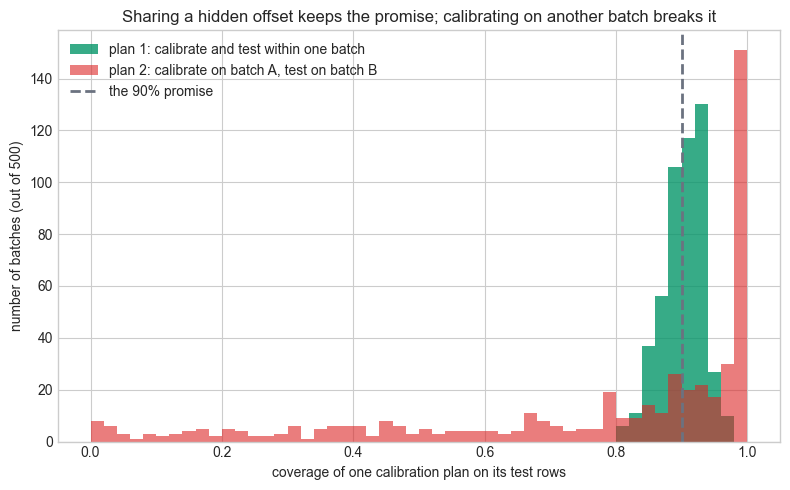

In [3]:
rng = np.random.default_rng(RANDOM_SEED + 1)
N_BATCHES, ROWS = 500, 400
theta = rng.normal(0.0, 1.0, size=(N_BATCHES, 1))              # one hidden offset per batch
rows = theta + rng.normal(0.0, 0.5, size=(N_BATCHES, ROWS))    # shared offset + own noise
batch_scores = np.abs(rows)                                    # residual of an offset-blind forecaster

corr_within = np.corrcoef(rows[:, 0], rows[:, 1])[0, 1]               # two rows, same batch
corr_across = np.corrcoef(rows[:, 0], np.roll(rows[:, 0], 1))[0, 1]   # same row, neighbouring batches

# Plan 1: calibrate on rows 0-198 of batch j, test on rows 200-399 of the SAME batch.
within = np.array([coverage_of(batch_scores[j, :199], batch_scores[j, 200:])
                   for j in range(N_BATCHES)])
# Plan 2: calibrate on rows 0-198 of batch j, test on rows 200-399 of batch j + 1.
across = np.array([coverage_of(batch_scores[j, :199], batch_scores[(j + 1) % N_BATCHES, 200:])
                   for j in range(N_BATCHES)])

print(f"correlation of two rows in the same batch:      {corr_within:.3f}")
print(f"correlation of two rows in different batches:   {corr_across:.3f}")
for name, cov in [("plan 1, within a batch", within), ("plan 2, across batches", across)]:
    p5, p95 = np.percentile(cov, [5, 95])
    print(f"{name}: mean coverage {cov.mean():.3f} | 5th-95th percentile over 500 batches "
          f"[{p5:.3f}, {p95:.3f}]")

fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(0.0, 1.0, 51)
ax.hist(within, bins=bins, color=GREEN, alpha=0.8, label="plan 1: calibrate and test within one batch")
ax.hist(across, bins=bins, color=RED, alpha=0.6, label="plan 2: calibrate on batch A, test on batch B")
ax.axvline(1 - ALPHA, color=GRAY, ls="--", lw=2, label="the 90% promise")
ax.set_title("Sharing a hidden offset keeps the promise; calibrating on another batch breaks it")
ax.set_xlabel("coverage of one calibration plan on its test rows")
ax.set_ylabel("number of batches (out of 500)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Neither check got both plans right. Two rows of the same batch are correlated at 0.793, yet plan 1 covers 0.901 on average, with the ordinary lottery of a 199-score calibration set around it (5th-95th percentile 0.845 to 0.950: notebook 03, section 5). The strict check threw that plan away, and so did the shortcut. Rows of different batches are independent (correlation 0.028, noise around zero), which is all the shortcut looked at, yet plan 2 covers 0.761 on average, and its spread is no longer a lottery but a coin you cannot see. When the calibration batch happens to have a small offset and the test batch a large one, the band covers almost nothing (the 5th percentile is 0.134); in the reverse pairing it covers everything (the 95th percentile is 1.000). The red tower at 1.0 and the long red tail are the same mistake seen from both ends.

The question that gets both verdicts right is not "are the rows independent?" in any form, but "could a test row swap places with a calibration row without changing anything?"

| Plan | Strict i.i.d. check (all rows) | The shortcut (test set independent of calibration set, same marginals) | The swap question | Measured coverage |
|---|---|---|---|---|
| Within a batch | reject: every row shares $\theta_j$. Too strict: the plan is valid | reject: test rows are correlated with calibration rows. Wrong | valid: every row shares the same $\theta_j$, so any two can swap unnoticed | 0.901 |
| Across batches | reject: the calibration rows share $\theta_A$. Right, but it said the same about plan 1 | accept: batch B is independent of batch A. Wrong | broken: the calibration rows share $\theta_A$ with each other and the test row does not | 0.761 |

The strict check is safe but uninformative here: it rejects both plans, so it cannot tell the valid one from the broken one. The shortcut is informative and wrong both times. Only the swap question separates them.

The theory behind the table has a name. **De Finetti's theorem** says, in plain words, that an endless exchangeable sequence behaves exactly as if nature first drew a hidden parameter (this batch's offset, this building's character) and then produced independent, identically distributed draws given that parameter. In symbols, after the words:

$$\Pr(Z_1 \in A_1, \dots, Z_n \in A_n) = \int \prod_{i=1}^{n} P_\theta(A_i)\, \mu(d\theta),$$

where $Z_1, \dots, Z_n$ are the rows, $A_1, \dots, A_n$ any sets of values, $\theta$ the hidden parameter, $\mu$ the distribution nature draws it from, and $P_\theta$ the distribution of one row given $\theta$. Read it as "independent given $\theta$, correlated through $\theta$". Plan 1 lives inside one draw of $\theta$, so every row, calibration or test, shares it: exchangeable, and the guarantee holds. Plan 2 makes the test row the one row with a different $\theta$: a special position, exactly what the leaderboard argument forbids. Conformal prediction never needed independence. It needs "no position is special".

One more example, even smaller, shows that exchangeable sequences need not even fit de Finetti's picture. Draw tiles one at a time, without replacement, from a pool of three red and two blue tiles, and ask whether "red" at one position tells you anything about another.

In [4]:
pool = ["red", "red", "red", "blue", "blue"]
orders = list(itertools.permutations(range(len(pool))))     # all 120 draw orders, equally likely
is_red = np.array([[pool[i] == "red" for i in order] for order in orders])

print("P(red) at draw 1..5:", ", ".join(f"{p:.2f}" for p in is_red.mean(axis=0)))
print(f"P(draw 2 is red | draw 1 is red) = {is_red[is_red[:, 0], 1].mean():.2f}"
      f"   versus P(draw 2 is red) = {is_red[:, 1].mean():.2f}")
print(f"correlation between draw 1 and draw 2 being red: "
      f"{np.corrcoef(is_red[:, 0], is_red[:, 1])[0, 1]:.2f}")

P(red) at draw 1..5: 0.60, 0.60, 0.60, 0.60, 0.60
P(draw 2 is red | draw 1 is red) = 0.50   versus P(draw 2 is red) = 0.60
correlation between draw 1 and draw 2 being red: -0.25


Every position has the same chance of red, 0.60, and in fact every ordering of the five tiles is equally likely: the sequence is exchangeable. It is also plainly dependent: once the first draw is red, the second is red with probability 0.50, not 0.60, and the two draws are correlated at -0.25. That negative correlation is the tell that this sequence is not a mixture of i.i.d. draws at all: in de Finetti's picture, two rows share $\theta$ and can only be positively correlated (or uncorrelated). The urn is exchangeable without the theorem's help, and the leaderboard argument does not care, because it uses only the symmetry.

This is not a curiosity. A random train / calibration / test split of a fixed dataset is precisely sampling without replacement from a finite pool. Treat the dataset you happen to hold as that pool, and its rows are no longer independent of each other, yet they are perfectly exchangeable, which is all a random split like notebook 02's needs. Whenever you hear "conformal needs i.i.d.", translate it to "conformal needs the calibration rows and the test row to be swappable", and then ask how the rows were chosen.

## 3. Exchangeable at which level?

The batch picture is not a toy for Kestrel. Replace "batch" by "building" and "offset" by everything that makes one building different from another: its size, its occupancy, how erratic its HVAC is. The forecasting project meets this question in its first week. The team has bands calibrated on the buildings it already meters, and facilities asks for bands on a building that joined the portfolio yesterday.

We simulate a portfolio of 11 buildings over 120 days with the course's shared simulators, copied verbatim below: `simulate_building_load` (one building, hourly) and `simulate_building_portfolio` (many buildings with different parameters), plus `make_direct_table`, which turns a series into a table with one row per hour at which a forecast is issued and the target `h` hours later. Notebook 10 introduces that table properly; here we need only two of its columns. Read the docstrings: later notebooks test the claims they make.

The forecaster is the facilities lead's ten-year habit, "same hour last week", issued a day ahead (`h = 24`). The score is its relative error, `|target - same_time_last_week| / same_time_last_week`. A relative score is scale-free, so a 100 kWh building and a 500 kWh building speak the same language, and pooling their scores is not obviously silly. The experiment is leave one building out: calibrate on all rows of ten buildings, measure coverage on every row of the eleventh, and repeat for each building in turn.

In [5]:
def simulate_building_load(n_days, seed, start="2016-01-01", base_kwh=120.0,
                           occupied_kwh=180.0, hvac_kwh_per_deg=6.0, noise_frac=0.06,
                           shift_day=None, shift_frac=0.0):
    """Simulate an hourly electricity meter for one Kestrel office building.

    What the simulator bakes in (and what later notebooks test against):
    - A daily occupancy profile: busy 08:00-18:00 on weekdays, quiet nights and weekends.
      That is why 'same hour yesterday' and 'same hour last week' are strong baselines.
    - Heating and cooling: load rises when the outdoor temperature leaves a comfort zone,
      and the temperature follows the seasons, so summer and winter behave differently.
    - Noise that is autocorrelated (a busy morning tends to stay busy) and larger when the
      building is occupied. Residuals are neither independent nor equal-sized.
    - Optional regime change: from day `shift_day` on, the load level is multiplied by
      (1 + shift_frac) - a new tenant, a retrofit. Notebook 15 uses it to break calibration.

    Returns a DataFrame indexed by hourly timestamp with columns `load_kwh` and `temp_c`.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, periods=24 * n_days, freq="h")
    n = len(idx)
    hour = idx.hour.to_numpy()
    dow = idx.dayofweek.to_numpy()
    doy = idx.dayofyear.to_numpy()

    # Weather: seasons + a daily cycle + persistent anomalies (a cold week stays cold).
    anomaly = np.zeros(n)
    shocks = rng.normal(0.0, 0.6, size=n)
    for i in range(1, n):
        anomaly[i] = 0.97 * anomaly[i - 1] + shocks[i]
    temp = 12.0 - 10.0 * np.cos(2 * np.pi * (doy - 15) / 365.25) \
        + 4.0 * np.sin(2 * np.pi * (hour - 9) / 24) + anomaly

    # Occupancy: weekdays 08-18, with half-occupied shoulder hours at 07 and 18.
    occupied = ((dow < 5) & (hour >= 8) & (hour < 18)).astype(float)
    shoulder = ((dow < 5) & ((hour == 7) | (hour == 18))).astype(float) * 0.5
    occ = occupied + shoulder

    hvac = hvac_kwh_per_deg * (1.3 * np.maximum(temp - 22.0, 0.0)
                               + np.maximum(16.0 - temp, 0.0)) * (0.4 + 0.6 * occ)
    mean_load = base_kwh + occupied_kwh * occ + hvac

    # Autocorrelated, occupancy-dependent multiplicative noise.
    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.8 * ar[i - 1] + math.sqrt(1 - 0.8 ** 2) * z[i]
    load = mean_load * (1.0 + noise_frac * (1.0 + occ) * ar)

    if shift_day is not None:
        load = np.where(np.arange(n) >= 24 * shift_day, load * (1.0 + shift_frac), load)
    return pd.DataFrame({"load_kwh": np.maximum(load, 0.0), "temp_c": temp}, index=idx)


def simulate_building_portfolio(n_buildings, n_days, seed):
    """Simulate a portfolio of Kestrel buildings that differ in size, occupancy and HVAC.

    Each building gets its own parameters and its own random seed, so the portfolio looks
    like a set of real sites: same physics, different scales. Notebook 12 pre-trains a
    'global' model on a portfolio and applies it zero-shot to a building it never saw.
    Returns a dict {building_name: DataFrame from simulate_building_load}.
    """
    rng = np.random.default_rng(seed)
    portfolio = {}
    for i in range(n_buildings):
        portfolio[f"building_{i:02d}"] = simulate_building_load(
            n_days, seed=int(rng.integers(1_000_000)),
            base_kwh=float(rng.uniform(40, 250)),
            occupied_kwh=float(rng.uniform(60, 400)),
            hvac_kwh_per_deg=float(rng.uniform(2, 12)),
            noise_frac=float(rng.uniform(0.04, 0.09)))
    return portfolio


def make_direct_table(y, h, period, exog=None):
    """Turn a series into a supervised table for forecasting h steps ahead.

    One row per forecast origin t. Every feature uses only values known at time t
    (y[t], y[t-1], ...); the target is y[t + h]. `period` is the number of steps per day
    (24 for hourly meters, 288 for 5-minute CPU). Requires h <= period, so that 'same time
    yesterday' (relative to the target) is already observed at the origin.

    The four simple baselines and the past-percentile reference band are columns of this
    table, computed with exactly the same no-peeking rule as the model features.
    """
    assert h <= period, "h must not exceed one day, or 'same time yesterday' is in the future"
    v = y.to_numpy(dtype=float)
    n = len(v)
    target_pos = np.arange(n) + h

    def at(offset):
        """Value at position (t + offset) for every origin t; NaN when out of range."""
        pos = np.arange(n) + offset
        out = np.full(n, np.nan)
        ok = (pos >= 0) & (pos < n)
        out[ok] = v[pos[ok]]
        return out

    same_time_past_days = np.column_stack([at(h - k * period) for k in range(1, 15)])
    table = pd.DataFrame({
        "last_value": v,
        "mean_last_day": pd.Series(v).rolling(period).mean().to_numpy(),
        "same_time_yesterday": same_time_past_days[:, 0],
        "same_time_last_week": same_time_past_days[:, 6],
        "median_14d_same_time": np.median(same_time_past_days, axis=1),
        "p05_14d_same_time": np.percentile(same_time_past_days, 5, axis=1),
        "p95_14d_same_time": np.percentile(same_time_past_days, 95, axis=1),
    }, index=y.index)
    target_time = y.index + h * (y.index[1] - y.index[0])
    table["target_hour"] = target_time.hour + target_time.minute / 60.0
    table["target_dow"] = target_time.dayofweek
    if exog is not None:
        # Treated as a forecast known in advance (e.g. tomorrow's weather forecast).
        e = exog.to_numpy(dtype=float)
        exog_at_target = np.full(n, np.nan)
        ok = target_pos < n
        exog_at_target[ok] = e[target_pos[ok]]
        table["exog_at_target"] = exog_at_target
    table["target"] = at(h)
    table["target_time"] = target_time
    return table.dropna().copy()

In [6]:
portfolio = simulate_building_portfolio(11, 120, seed=RANDOM_SEED)

site_scores, mean_kwh = {}, {}
for name, building in portfolio.items():
    tab = make_direct_table(building["load_kwh"], h=24, period=24)
    # Relative day-ahead error of 'same hour last week': scale-free, so sites can be pooled.
    site_scores[name] = (np.abs(tab["target"] - tab["same_time_last_week"])
                         / tab["same_time_last_week"]).to_numpy()
    mean_kwh[name] = building["load_kwh"].mean()

rows = []
for name in portfolio:
    # Leave one building out: the calibration pool is every row of the OTHER ten sites.
    pool_scores = np.concatenate([site_scores[k] for k in portfolio if k != name])
    rows.append({
        "building": name,
        "mean_kwh": mean_kwh[name],
        "rows": len(site_scores[name]),
        # A description of the site, not a conformal threshold: method="higher" returns an
        # actual score with at least 90% of the building's own rows at or below it.
        "own_p90_score": float(np.quantile(site_scores[name], 0.9, method="higher")),
        "q_hat_from_other_ten": corrected_quantile(pool_scores, ALPHA),
        "coverage": coverage_of(pool_scores, site_scores[name]),
    })
lobo = pd.DataFrame(rows).set_index("building")

print(f"calibration pool per fold: about {10 * lobo['rows'].iloc[0]:,} rows from ten buildings")
print(f"mean coverage over the 11 held-out buildings: {lobo['coverage'].mean():.3f}")
print(f"range across buildings: {lobo['coverage'].min():.3f} "
      f"({lobo['coverage'].idxmin()}) to {lobo['coverage'].max():.3f} ({lobo['coverage'].idxmax()})")
lobo.round(3)

calibration pool per fold: about 25,440 rows from ten buildings
mean coverage over the 11 held-out buildings: 0.899
range across buildings: 0.812 (building_03) to 0.954 (building_04)


,mean_kwh,rows,own_p90_score,q_hat_from_other_ten,coverage
building,,,,,
building_00,273.762,2544,0.232,0.219,0.878
building_01,338.799,2544,0.252,0.218,0.862
building_02,280.901,2544,0.261,0.217,0.845
building_03,264.489,2544,0.272,0.215,0.812
building_04,249.408,2544,0.175,0.224,0.954
building_05,190.503,2544,0.179,0.224,0.949
building_06,209.102,2544,0.240,0.218,0.864
building_07,267.925,2544,0.212,0.221,0.914
building_08,334.855,2544,0.198,0.223,0.934


The tempting summary of this experiment is one number: averaged over the 11 held-out buildings, coverage is 0.899, so "a new building gets a 90% band". The table refuses that summary. Coverage runs from 0.812 on `building_03` to 0.954 on `building_04`, and the column that explains it is `own_p90_score`, each building's own 90th-percentile relative error. The pooled threshold barely moves between folds (0.215 to 0.224: leaving one site out of eleven hardly changes the pool), so a building whose own errors run above it, such as `building_03` at 0.272, is under-covered, and a calm one, such as `building_04` at 0.175, is over-covered. With 2,544 rows per building, these gaps are not sampling noise. The hourly errors are autocorrelated, so the honest noise band is wider than the textbook binomial one (about 0.012 for independent rows), but nowhere near wide enough to turn 0.812 into 0.90. These are real differences between sites.

So at which level is the shuffle plausible? The buildings are exchangeable with each other: `simulate_building_portfolio` draws every site's parameters the same way, so a new building is like a randomly chosen one. The rows across buildings are not: rows of `building_03` share `building_03`'s noisiness, which is section 2's hidden $\theta$ wearing a hard hat. The promise therefore lives at the building level and in the building-level sense only: averaged over many new buildings it is kept, approximately (0.899 here; pooling rows from equally sized sites is a close approximation rather than a finite-sample theorem, and the one-score-per-building construction below is exact), and for any single new building it is a lottery ticket (notebook 03, section 5) and a slice (notebook 03, section 6). That is field guide §13 in one table.

If facilities needs a promise per building, not per portfolio, we can calibrate at the building level instead. Treat each building as one tile: give it one score, its own 90th-percentile error, and run the leaderboard argument on buildings. With ten calibration buildings, the corrected quantile of ten building scores at `ALPHA = 0.10` is their maximum, and the rank argument says a new building's own 90th percentile falls at or below it with probability at least 10/11 = 0.909. Whenever it does, at least 90% of that building's rows are covered. The two 90%s are separate dials: one is the coverage within a building, the other the probability over which building turns up.

row-level pool:      buildings at or above 0.90: 6 of 11 | mean threshold 0.220
building-level tile: buildings at or above 0.90: 10 of 11 | mean threshold 0.271 | mean coverage 0.948
price of the per-building promise: a band 23% wider


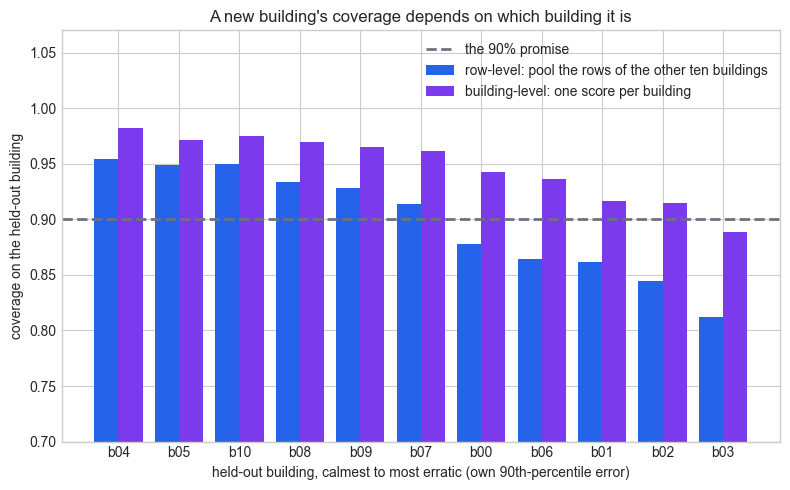

In [7]:
own_p90 = lobo["own_p90_score"]
lobo["q_hat_building_level"] = [corrected_quantile(own_p90.drop(name).to_numpy(), ALPHA)
                                for name in lobo.index]
lobo["coverage_building_level"] = [float(np.mean(site_scores[name] <= lobo.loc[name, "q_hat_building_level"]))
                                   for name in lobo.index]
n_ok = int((lobo["coverage_building_level"] >= 1 - ALPHA).sum())
print(f"row-level pool:      buildings at or above 0.90: {(lobo['coverage'] >= 1 - ALPHA).sum()} of 11"
      f" | mean threshold {lobo['q_hat_from_other_ten'].mean():.3f}")
print(f"building-level tile: buildings at or above 0.90: {n_ok} of 11"
      f" | mean threshold {lobo['q_hat_building_level'].mean():.3f}"
      f" | mean coverage {lobo['coverage_building_level'].mean():.3f}")
width_cost = lobo["q_hat_building_level"].mean() / lobo["q_hat_from_other_ten"].mean() - 1
print(f"price of the per-building promise: a band {width_cost:.0%} wider")

order = lobo.sort_values("own_p90_score").index
pos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(pos - 0.2, lobo.loc[order, "coverage"], width=0.4, color=BLUE,
       label="row-level: pool the rows of the other ten buildings")
ax.bar(pos + 0.2, lobo.loc[order, "coverage_building_level"], width=0.4, color=PURPLE,
       label="building-level: one score per building")
ax.axhline(1 - ALPHA, color=GRAY, ls="--", lw=2, label="the 90% promise")
ax.set_xticks(pos)
ax.set_xticklabels([b.replace("building_", "b") for b in order])
ax.set_ylim(0.7, 1.07)
ax.set_title("A new building's coverage depends on which building it is")
ax.set_xlabel("held-out building, calmest to most erratic (own 90th-percentile error)")
ax.set_ylabel("coverage on the held-out building")
ax.legend(loc="upper right", framealpha=0.95)
plt.tight_layout()
plt.show()

The blue bars fall, almost monotonically, from left to right: the more erratic the held-out building, the less the pooled band covers it, from 0.954 on the calmest site to 0.812 on the most erratic, with 5 of 11 buildings below 0.90. The purple bars are the building-level promise at work: 10 of 11 buildings get at least 0.90, mean 0.948. The one exception is `building_03`, the building with the largest own error, which cannot sit below the maximum of the other ten. That is exactly the one-in-eleven failure the rank argument allows. The price is width: the building-level threshold averages 0.271 against 0.220 for the row-level pool, a band 23% wider for every building, the calm ones included.

Two practical rules follow, and the forecasting project should adopt both. First, split at the level you will deploy at: when the question is "a new building", evaluate with group-aware splits (leave one building out, or scikit-learn's `GroupKFold` with the building as the group) and never let rows of the test building into training or calibration (notebook 12 meets the same leak in a pre-trained model). Second, choose the promise deliberately. The row-level pool promises about 90% on average over new sites; the building-level tile promises at least 90% for a new site with probability at least 90% (10/11 with our ten sites), and it needs many sites: with fewer than nine calibration buildings, `corrected_quantile` refuses to produce a 90% building-level threshold at all. Dunn, Wasserman and Ramdas (2023) study this two-layer setting in depth.

## 4. The zoo of violations

Notebook 03 broke the guarantee once, with a sorted file, and notebook 07 repaired one specific break, covariate shift. A thesis needs the whole map. We now break exchangeability six ways, each with a few lines of simulation, each measured with the same `coverage_of` helper.

To keep the comparison clean, four of the six demos share one small world. A heat index $x$ in $[0, 1]$ drives a building's load, $y = 2 + 3x$ plus noise whose spread grows with $x$ (hot days are erratic). The forecaster is a perfect model of the calibration world, $\hat y = 2 + 3x$, frozen. A perfect model isolates the assumption: whatever coverage is lost below is lost to how rows were chosen, never to a bad fit. The score is notebook 02's absolute error $|y - \hat y|$. Each demo draws 2,000 rows for calibration and 2,000 for testing (in (f) only about half of the calibration rows ever get a label). The noise of one coverage number is then about $\pm 0.02$ (two standard deviations), because the test rows and the calibration draw each contribute about as much wobble.

The demos: (a) time order with drift, where the noise widens slowly along the stream and we calibrate on the past; (b) covariate shift, where hotter days arrive but the rule is unchanged; (d) concept drift, where the same days arrive but the rule moved; (f) selection and feedback, where the business only learns outcomes for the cases it acted on. Label shift (c) needs a classifier and gets its own cell; groups (e) is section 3. For (b) and (d) we also run notebook 07's domain classifier, a logistic regression asked to tell old inputs from new ones; an AUC of 0.50 means it cannot.

In [8]:
def frozen_model(x):
    """The forecaster every demo in this section shares: a PERFECT model of the
    calibration world, where load rises linearly with a heat index x in [0, 1].
    A perfect model isolates the assumption: whatever coverage is lost below is lost to
    how the rows were chosen, never to a bad fit."""
    return 2.0 + 3.0 * x


def observe(x, rng, spread=1.0, extra=0.0):
    """Draw outcomes for inputs x. The noise grows with x (hot days are erratic), which
    is what lets a change in WHICH x values arrive move the scores (notebook 07,
    section 3). `spread` widens the noise (drift in time); `extra` changes the
    relationship itself (concept drift)."""
    return frozen_model(x) + extra + spread * (0.2 + 1.0 * x) * rng.normal(size=len(x))


def abs_score(x, y):
    """Notebook 02's nonconformity score: the absolute error of the frozen model."""
    return np.abs(y - frozen_model(x))


def domain_auc(x_old, x_new):
    """Notebook 07's shift detector: can a logistic regression tell old inputs from new
    ones? Fit on even rows, measure AUC on odd rows; 0.50 means indistinguishable."""
    X = np.concatenate([x_old, x_new]).reshape(-1, 1)
    is_new = np.r_[np.zeros(len(x_old)), np.ones(len(x_new))]
    fit_rows = np.arange(len(X)) % 2 == 0
    clf = LogisticRegression().fit(X[fit_rows], is_new[fit_rows])
    return float(roc_auc_score(is_new[~fit_rows], clf.predict_proba(X[~fit_rows])[:, 1]))


rng = np.random.default_rng(RANDOM_SEED + 3)
N = 2_000
measured = {}

# (a) Time order with drift: one stream of 2N rows whose noise widens by 60% from the
#     first row to the last. Calibrate on the first N rows (the past), test on the rest.
x = rng.uniform(0.0, 1.0, 2 * N)
s = abs_score(x, observe(x, rng, spread=1.0 + 0.6 * np.arange(2 * N) / (2 * N)))
measured["a"] = coverage_of(s[:N], s[N:])
shuffle = rng.permutation(2 * N)        # control: the SAME rows, roles assigned at random
control_a = coverage_of(s[shuffle[:N]], s[shuffle[N:]])

# (b) Covariate shift: calibrated on a mild mix of days, deployed in a hot summer.
#     Same rule, same noise; only WHICH x values arrive changes.
x_cal, x_new = rng.uniform(0.0, 1.0, N), rng.beta(3.0, 1.0, N)
measured["b"] = coverage_of(abs_score(x_cal, observe(x_cal, rng)),
                            abs_score(x_new, observe(x_new, rng)))
auc_b = domain_auc(x_cal, x_new)

# (d) Concept drift: the SAME mix of days, but the rule moved - a degraded chiller now
#     draws a third more load per unit of heat (slope 3 -> 4). The model stays frozen.
x_cal, x_new = rng.uniform(0.0, 1.0, N), rng.uniform(0.0, 1.0, N)
measured["d"] = coverage_of(abs_score(x_cal, observe(x_cal, rng)),
                            abs_score(x_new, observe(x_new, rng, extra=1.0 * x_new)))
auc_d = domain_auc(x_cal, x_new)

# (f) Selection and feedback: outcomes are learned only where the business ACTED, and it
#     acts where its own forecast is below a budget line (forecast < 3.5, i.e. x < 0.5).
x = rng.uniform(0.0, 1.0, 2 * N)
s = abs_score(x, observe(x, rng))
acted = frozen_model(x) < 3.5
cal_f = s[:N][acted[:N]]                                   # the only labels ever seen
measured["f"] = coverage_of(cal_f, s[N:])                  # the population it quotes bands for
acted_only_f = coverage_of(cal_f, s[N:][acted[N:]])

print(f"(a) time order with drift: past -> future {measured['a']:.3f} | "
      f"same rows shuffled {control_a:.3f}")
print(f"(b) covariate shift:       coverage {measured['b']:.3f} | domain classifier AUC {auc_b:.3f}")
print(f"(d) concept drift:         coverage {measured['d']:.3f} | domain classifier AUC {auc_d:.3f}")
print(f"(f) selection:             cases acted on {acted_only_f:.3f} | full population "
      f"{measured['f']:.3f} | share of rows with a label {acted[:N].mean():.0%}")

(a) time order with drift: past -> future 0.822 | same rows shuffled 0.901
(b) covariate shift:       coverage 0.823 | domain classifier AUC 0.748
(d) concept drift:         coverage 0.849 | domain classifier AUC 0.509
(f) selection:             cases acted on 0.912 | full population 0.763 | share of rows with a label 50%


Read the four lines as four different stories about the same frozen, perfect model.

(a) Calibrating on the first half of a slowly drifting stream and testing on the second half delivers 0.822. The control, the same 4,000 rows with their roles assigned at random, delivers 0.901: nothing is wrong with the rows themselves, only with the fact that the test rows all come later. This is notebook 03's sorted-split break with time as the sort key, and time is the one sort key you cannot shuffle away. (b) Hotter days arrive, the rule is unchanged, and coverage falls to 0.823, because hot days are where the noise lives (notebook 07, section 3). The domain classifier sees it immediately, AUC 0.748, and notebook 07 turned that same classifier into the repair. (d) Concept drift costs a little less here, 0.849, but the domain classifier is blind to it: AUC 0.509, chance level, because the inputs did not change, only what they mean. No reweighting of old scores can repair a rule that no longer exists; the only cure is new labels (field guide §10). (f) Selection is the quiet one. On the cases the business acted on, the band is fine, 0.912, which is what any dashboard built from labelled data would show. On the full population it quotes bands for, coverage is 0.763, because the labels came only from the calm half of the world.

One trap in (f) deserves a sentence of its own: it looks like covariate shift, but the reweighting repair is impossible here. Cases above the budget line have probability zero of ever being labelled, so the likelihood ratio of notebook 07 is undefined for them: the absolute-continuity cliff of notebook 07, section 7. The repair is to make the selection random somewhere: label a small random sample of the cases you did not act on, or randomize the decision near the line and log the probability, so that inverse-probability weights exist. Hearthstone, the property-tech startup of Part I, would face exactly this: it only learns the true value of the homes it bought. Kestrel faces it with alarms: it only learns whether an alarm was a real fault for the alarms someone investigated.

Label shift needs a classifier. Kestrel's on-call engineers label each alarm as a real fault or a nuisance, and a logistic regression learns to tell them apart from one feature (how far the reading strayed from normal). In a normal week 20% of alarms are real faults; in a heatwave the share triples to 60%. What a real fault looks like, $P(x \mid y)$, never changes: only the mix $P(y)$ does. We use notebook 04's LAC score, one minus the probability the model gave the true label, and compare one shared bar with notebook 04's class-conditional (Mondrian) bars, one per true class.

In [9]:
def draw_alarms(n, share_real, rng):
    """Simulate n alarms with one feature x: how far the reading strayed from normal.

    Real faults (label 1) stray further than nuisance alarms (label 0), with overlap.
    What a real fault LOOKS like, P(x | label), is fixed forever; only the share of real
    faults among alarms changes. That is label shift.
    Returns x as an (n, 1) array and the 0/1 labels.
    """
    label = (rng.random(n) < share_real).astype(int)
    x = np.where(label == 1, rng.normal(1.5, 1.0, n), rng.normal(0.0, 1.0, n))
    return x.reshape(-1, 1), label


def lac_scores(model, X, label):
    """Notebook 04's LAC score: one minus the probability the model gave the TRUE label."""
    return 1.0 - model.predict_proba(X)[np.arange(len(label)), label]


rng = np.random.default_rng(RANDOM_SEED + 4)
OLD_SHARE, NEW_SHARE = 0.20, 0.60     # share of real faults: a normal week vs a heatwave
X_fit, lab_fit = draw_alarms(3_000, OLD_SHARE, rng)
alarm_model = LogisticRegression().fit(X_fit, lab_fit)
X_cal, lab_cal = draw_alarms(2_000, OLD_SHARE, rng)
s_cal = lac_scores(alarm_model, X_cal, lab_cal)

rows = []
for mix, share in [("normal week (20% real)", OLD_SHARE), ("heatwave (60% real)", NEW_SHARE)]:
    X_te, lab_te = draw_alarms(4_000, share, rng)
    s_te = lac_scores(alarm_model, X_te, lab_te)
    per_class_shared = [coverage_of(s_cal, s_te[lab_te == k]) for k in (0, 1)]
    # Class-conditional calibration (notebook 04): each TRUE class gets its own bar.
    per_class_own = [coverage_of(s_cal[lab_cal == k], s_te[lab_te == k]) for k in (0, 1)]
    weights = np.array([np.mean(lab_te == 0), np.mean(lab_te == 1)])
    rows.append({
        "test mix": mix,
        "overall, shared bar": coverage_of(s_cal, s_te),
        "nuisance, shared bar": per_class_shared[0],
        "real fault, shared bar": per_class_shared[1],
        "overall, per-class bars": float(weights @ per_class_own),
        "real fault, per-class bars": per_class_own[1],
    })
label_shift = pd.DataFrame(rows).set_index("test mix")
measured["c"] = label_shift.loc["heatwave (60% real)", "overall, shared bar"]
print(f"calibration alarms: {len(lab_cal):,}, of which real faults: {lab_cal.sum()} "
      f"(the only scores behind the real-fault bar)")
label_shift.round(3)

calibration alarms: 2,000, of which real faults: 415 (the only scores behind the real-fault bar)


,"overall, shared bar","nuisance, shared bar","real fault, shared bar","overall, per-class bars","real fault, per-class bars"
test mix,,,,,
normal week (20% real),0.912,0.980,0.629,0.905,0.896
heatwave (60% real),0.752,0.983,0.604,0.885,0.873


With one shared bar, the per-class coverages are the same in both weeks up to test-set noise: nuisance alarms 0.980 and 0.983, real faults 0.629 and 0.604. They have to be, because with the model, the scores and the bar all fixed, each class's coverage depends only on $P(x \mid y)$, which did not move. What moves is the overall number, because it is a weighted average of the two and the weights changed: 0.912 in a normal week, where the easy class dominates, and 0.752 in the heatwave, where the hard class does. The shared bar never covered real faults at 90%, which is notebook 04's rare-class failure; label shift merely promotes that hidden failure to the headline.

Class-conditional calibration answers it for any mix: each class is promised at least 90% on its own, so every weighted average of the classes is promised at least 90% too. In the heatwave it lifts the overall number from 0.752 to 0.885 and real faults from 0.604 to 0.873. One caution about reading those last two numbers as a failure: the real-fault bar was set from only 415 calibration scores, and a single calibration set of that size is a lottery ticket that routinely lands a couple of points either side of 0.90 (notebook 03, section 5, where 200 scores spanned 0.865 to 0.935). The same bar delivered 0.896 on the normal week's real faults; this ticket is a little short, and a larger real-fault calibration set is the only thing that narrows it. The price of per-class bars, as in notebook 04, is longer sets for the class that was being shortchanged. The alternative repair is to reweight the calibration scores by the ratio of new to old class shares, which requires knowing the new mix (or estimating it from unlabelled alarms).

In [10]:
pd.set_option("display.max_colwidth", 120)   # this one table is mostly text: let it breathe
zoo = pd.DataFrame([
    {"Violation": "(a) Time order with drift",
     "What changes": "the score distribution moves along the stream",
     "Everyday example": "errors widen as the season turns; calibrate on spring, serve summer",
     "Measured coverage": f"{measured['a']:.3f} (shuffled control {control_a:.3f})",
     "Repair": "recalibration windows; online calibration (ACI, conformal PID)",
     "Where": "notebook 15"},
    {"Violation": "(b) Covariate shift",
     "What changes": "P(x) moves, P(y | x) fixed",
     "Everyday example": "more hot days than the calibration period had",
     "Measured coverage": f"{measured['b']:.3f}",
     "Repair": "weighted conformal with the likelihood ratio",
     "Where": "notebook 07"},
    {"Violation": "(c) Label shift",
     "What changes": "P(y) moves, P(x | y) fixed",
     "Everyday example": "the share of real faults among alarms triples in a heatwave",
     "Measured coverage": f"{measured['c']:.3f} (per class unchanged)",
     "Repair": "class-conditional calibration, or reweighting by class shares",
     "Where": "notebook 04"},
    {"Violation": "(d) Concept drift",
     "What changes": "P(y | x) moves",
     "Everyday example": "a degraded chiller: same heat, more kWh",
     "Measured coverage": f"{measured['d']:.3f} (domain AUC {auc_d:.2f})",
     "Repair": "no reweighting helps: new labels, retrain, recalibrate",
     "Where": "field guide §10, notebook 15"},
    {"Violation": "(e) Groups / new site",
     "What changes": "the test rows come from a group no calibration row belongs to",
     "Everyday example": "a building joins the portfolio",
     "Measured coverage": (f"{lobo['coverage'].min():.3f}-{lobo['coverage'].max():.3f} per building "
                           f"(mean {lobo['coverage'].mean():.3f})"),
     "Repair": "group-aware splits; building-level calibration",
     "Where": "section 3, field guide §13"},
    {"Violation": "(f) Selection and feedback",
     "What changes": "labels exist only where the business acted",
     "Everyday example": "true values only for homes bought; fault labels only for alarms investigated",
     "Measured coverage": f"{measured['f']:.3f} (acted-on cases {acted_only_f:.3f})",
     "Repair": "a random exploration sample; logged propensities, then inverse-probability weights",
     "Where": "notebook 07 machinery, field guide §6"},
]).set_index("Violation")
zoo

,What changes,Everyday example,Measured coverage,Repair,Where
Violation,,,,,
(a) Time order with drift,the score distribution moves along the stream,"errors widen as the season turns; calibrate on spring, serve summer",0.822 (shuffled control 0.901),"recalibration windows; online calibration (ACI, conformal PID)",notebook 15
(b) Covariate shift,"P(x) moves, P(y | x) fixed",more hot days than the calibration period had,0.823,weighted conformal with the likelihood ratio,notebook 07
(c) Label shift,"P(y) moves, P(x | y) fixed",the share of real faults among alarms triples in a heatwave,0.752 (per class unchanged),"class-conditional calibration, or reweighting by class shares",notebook 04
(d) Concept drift,P(y | x) moves,"a degraded chiller: same heat, more kWh",0.849 (domain AUC 0.51),"no reweighting helps: new labels, retrain, recalibrate","field guide §10, notebook 15"
(e) Groups / new site,the test rows come from a group no calibration row belongs to,a building joins the portfolio,0.812-0.954 per building (mean 0.899),group-aware splits; building-level calibration,"section 3, field guide §13"
(f) Selection and feedback,labels exist only where the business acted,true values only for homes bought; fault labels only for alarms investigated,0.763 (acted-on cases 0.912),"a random exploration sample; logged propensities, then inverse-probability weights","notebook 07 machinery, field guide §6"


Six violations: five coverage numbers below the promise, one spread that straddles it (row e: a portfolio mean of 0.899 over buildings that range from 0.812 to 0.954), and not one error message among them. That is field guide §6 in table form. The measured numbers are not a ranking of how dangerous each violation is; they depend on how hard we pushed each simulation. What does carry over to real data is the pattern in the "What changes" and "Repair" columns.

Three readings to take into the project. First, the repairs differ because the causes differ, so the first job is diagnosis, not a method: weighting fixes (b) and does nothing for (d); class-conditional bars fix (c) and do nothing for (a). Second, several violations are invisible to the checks people usually run. Concept drift (d) fooled the domain classifier (AUC 0.51), and selection (f) fools every metric computed on labelled data (0.912 on the cases acted on). Third, the Kestrel project lives in rows (a) and (e) by default: hourly meters are a time-ordered stream, and new buildings and VMs join the portfolio. Notebook 10 starts there.

## 5. How would anyone know? Three tests

The head of operations asked two questions, and section 4 answered only the first: yes, there are many ways for the meters not to qualify. The second question, "how would anyone know?", needs tests: field guide §14. We build three, from the cheapest to the most principled, on two synthetic streams of 2,000 nonconformity scores, one score per forecast as the truth arrives. In the steady stream, the scores are independent draws from one distribution, exchangeable by construction. In the shifted stream, a retrofit at step 1,000 makes every later error 60% larger. The first 500 scores of each stream play the calibration window.

**(a) Look.** Plot a rolling mean of the scores (window 100) and the rolling coverage of the band calibrated on the first 500 scores.

steady stream   q_hat from the first 500 scores: 1.519 | coverage on steps 1001-2000: 0.864
shifted stream  q_hat from the first 500 scores: 1.692 | coverage on steps 1001-2000: 0.712
lowest 100-step rolling coverage of the STEADY stream after calibration: 0.79
long-run coverage of the steady stream's band, P(|Z| <= 1.519): 0.871


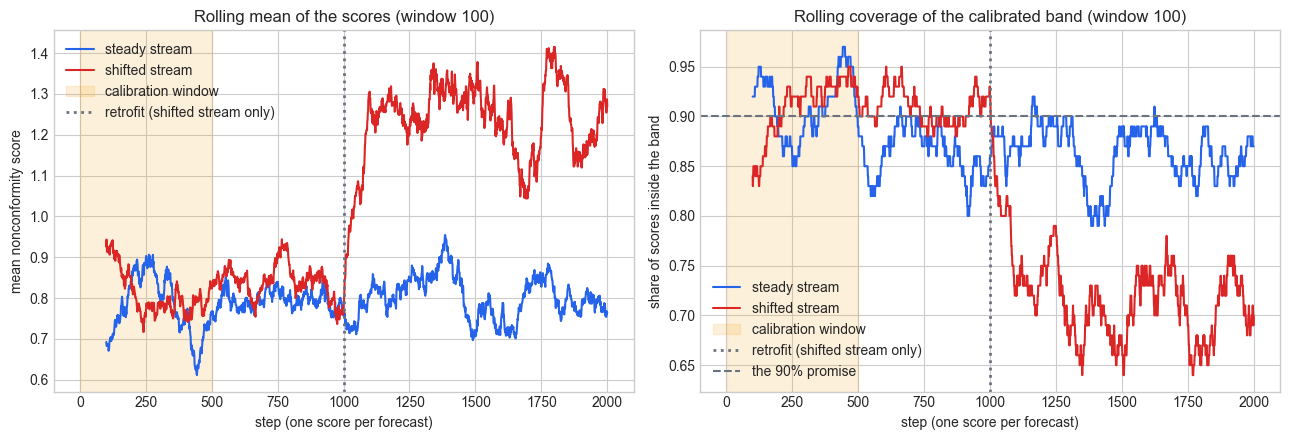

In [11]:
rng = np.random.default_rng(RANDOM_SEED + 5)
T, SHIFT_AT, CAL_LEN, WINDOW = 2_000, 1_000, 500, 100
after_shift = np.arange(T) >= SHIFT_AT
steady = np.abs(rng.normal(size=T))                                  # exchangeable by construction
shifted = np.abs(rng.normal(size=T)) * np.where(after_shift, 1.6, 1.0)  # errors 60% larger after step 1,000

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for stream, color, label in [(steady, BLUE, "steady stream"), (shifted, RED, "shifted stream")]:
    q_hat = corrected_quantile(stream[:CAL_LEN], ALPHA)
    hits = stream <= q_hat
    axes[0].plot(np.arange(1, T + 1), pd.Series(stream).rolling(WINDOW).mean(), color=color, label=label)
    axes[1].plot(np.arange(1, T + 1), pd.Series(hits.astype(float)).rolling(WINDOW).mean(),
                 color=color, label=label)
    print(f"{label:<15} q_hat from the first {CAL_LEN} scores: {q_hat:.3f} | coverage on steps "
          f"{SHIFT_AT + 1}-{T}: {hits[after_shift].mean():.3f}")
q_steady = corrected_quantile(steady[:CAL_LEN], ALPHA)
steady_hits = steady <= q_steady
lowest = pd.Series(steady_hits.astype(float)).rolling(WINDOW).mean().iloc[CAL_LEN + WINDOW:].min()
print(f"lowest {WINDOW}-step rolling coverage of the STEADY stream after calibration: {lowest:.2f}")
# The steady scores are |Z| for a standard normal Z, so this one band's long-run coverage is exact.
print(f"long-run coverage of the steady stream's band, P(|Z| <= {q_steady:.3f}): "
      f"{math.erf(q_steady / math.sqrt(2)):.3f}")

for ax in axes:
    ax.axvspan(1, CAL_LEN, color=AMBER, alpha=0.15, label="calibration window")
    ax.axvline(SHIFT_AT, color=GRAY, ls=":", lw=2, label="retrofit (shifted stream only)")
    ax.set_xlabel("step (one score per forecast)")
axes[1].axhline(1 - ALPHA, color=GRAY, ls="--", lw=1.5, label="the 90% promise")
axes[0].set_title(f"Rolling mean of the scores (window {WINDOW})")
axes[0].set_ylabel("mean nonconformity score")
axes[1].set_title(f"Rolling coverage of the calibrated band (window {WINDOW})")
axes[1].set_ylabel("share of scores inside the band")
axes[0].legend(loc="upper left")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

On the shifted stream the picture is unambiguous: the rolling mean steps up at the retrofit and the rolling coverage falls from around 0.90 to around 0.70 (0.712 over steps 1,001-2,000). On the steady stream nothing happened, yet its rolling coverage still wanders, down to 0.79 in its worst 100-step window, and its second half sits at 0.864. That is the lottery ticket of one 500-score calibration set, and an unlucky one: the steady scores are absolute values of standard normal draws, so the long-run coverage of this particular band can be computed exactly, and it is 0.871 (its `q_hat` of 1.519 landed below the scores' true 90th percentile). That is the weakness of looking: it is cheap and it should always be done first, but a dip to 0.79 is exactly what a healthy stream produces now and then, and the eye cannot tell a dip from a beginning. We need a number with a known false-alarm rate.

**(b) A permutation test.** The question: are the recent scores larger than the calibration scores? The statistic is the mean of the recent window minus the mean of the calibration window. If the stream is exchangeable, every way of splitting the pooled scores into a "calibration" group and a "recent" group of those sizes is equally likely, so shuffling the pooled scores and recomputing the statistic many times draws from its distribution under the null hypothesis. The p-value is the share of shuffles at least as extreme as the observed split, counting the observed split itself as one of them. We test the last 200 scores against the first 500.

In [12]:
def permutation_test(cal_scores, recent_scores, n_perm, rng):
    """One-sided permutation test: are the recent scores larger than the calibration ones?

    Statistic: mean(recent) - mean(calibration). Under exchangeability every split of the
    pooled scores into groups of these sizes is equally likely, so reshuffling the pooled
    scores draws the statistic from its null distribution. The +1 in the numerator and
    the denominator counts the observed split as one of the shuffles; it keeps the
    p-value valid (never below 1 / (n_perm + 1)). Valid for ONE look at the data.
    """
    pooled = np.concatenate([cal_scores, recent_scores])
    n_recent = len(recent_scores)
    observed = recent_scores.mean() - cal_scores.mean()
    shuffled = rng.permuted(np.tile(pooled, (n_perm, 1)), axis=1)
    null = shuffled[:, -n_recent:].mean(axis=1) - shuffled[:, :-n_recent].mean(axis=1)
    return float(observed), float((1 + np.sum(null >= observed)) / (n_perm + 1))


rng = np.random.default_rng(RANDOM_SEED + 6)
for stream, label in [(steady, "steady stream"), (shifted, "shifted stream")]:
    stat, p_value = permutation_test(stream[:CAL_LEN], stream[-200:], 9_999, rng)
    print(f"{label:<15} last 200 vs first {CAL_LEN}: difference in mean score {stat:+.3f} | "
          f"p-value {p_value:.4f}")

# The mistake everybody makes next: run the same 5% test every 100 steps, on healthy streams.
LOOKS = np.arange(700, T + 1, 100)       # 14 looks: steps 700, 800, ..., 2,000
healthy = np.abs(rng.normal(size=(200, T)))
alarms = np.array([[permutation_test(h[:CAL_LEN], h[t - 200:t], 199, rng)[1] <= 0.05 for t in LOOKS]
                   for h in healthy])
print(f"\n200 healthy streams, {len(LOOKS)} looks each at the 5% level:")
print(f"share of single looks that alarmed:       {alarms.mean():.3f}")
print(f"share of streams with at least one alarm: {alarms.any(axis=1).mean():.3f}")

steady stream   last 200 vs first 500: difference in mean score -0.013 | p-value 0.5929
shifted stream  last 200 vs first 500: difference in mean score +0.375 | p-value 0.0001



200 healthy streams, 14 looks each at the 5% level:
share of single looks that alarmed:       0.051
share of streams with at least one alarm: 0.370


As a one-shot instrument the permutation test is excellent. On the steady stream the last 200 scores are, if anything, slightly smaller than the first 500 (difference -0.013), p-value 0.593: quiet. On the shifted stream the difference is +0.375 and the p-value is 0.0001, the smallest value 9,999 shuffles can produce: loud. It needs no distributional assumption, the null distribution is built from the data, and its validity rests on the same symmetry as conformal prediction itself.

Then we committed the mistake everybody makes next: run it on a schedule. On 200 streams that are healthy by construction, each single look alarms at the advertised rate (0.051 of looks), but 0.370 of the streams raise at least one alarm in 14 looks. The 5% belongs to one look. A weekly monitoring job that runs a fixed-level test every week will eventually page someone about a stream that never changed. What we want is a test we are allowed to look at after every single score, with a false-alarm probability that holds for the whole life of the monitor.

**(c) A conformal test martingale.** The idea, in plain words first. Turn each new score into a p-value that asks "how unusual is this score compared with everything seen so far?". Then let a gambler bet against the hypothesis that these p-values behave the way exchangeability says they must. The gambler's wealth is the evidence: a fair game rarely makes anyone rich, and we can say in advance exactly how rarely.

Step one, the **smoothed conformal p-value**. Rank the newest score among all scores seen so far, itself included, counting from the top, and split ties (including the newest score's tie with itself) at random. In symbols:

$$p_n = \frac{\#\{i \le n : s_i > s_n\} \;+\; U_n \cdot \#\{i \le n : s_i = s_n\}}{n},$$

where $s_1, \dots, s_n$ are the scores so far, $s_n$ the newest, $\#$ counts, and $U_n$ is a fresh uniform random number on $(0, 1]$. The tie count is never zero, because $s_n$ ties with itself. This is notebook 03's leaderboard, rerun at every step. The theorem (Vovk, Nouretdinov and Gammerman 2003; Vovk, Gammerman and Shafer 2005): if the scores are exchangeable, $p_1, p_2, \dots$ are independent and uniform on $[0, 1]$. The random tie-break is what makes them exactly uniform instead of stuck on the grid $1/n, 2/n, \dots$.

Step two, the bet. At each step the gambler multiplies her wealth by a factor that exceeds 1 when the p-value is small (a surprisingly large score) and falls below 1 when it is large, priced so that its average under a uniform p-value is exactly 1: a fair bet. For a betting intensity $\varepsilon$ in $(0, 1]$ the factor $\varepsilon\, p^{\varepsilon - 1}$ does exactly that, since $\int_0^1 \varepsilon\, p^{\varepsilon-1}\, dp = 1$. A **martingale** is the running wealth of a fair game: its expected next value, given everything so far, equals its current value. Starting from wealth 1, after $n$ steps the **power martingale** is

$$M_n(\varepsilon) = \prod_{i=1}^{n} \varepsilon\, p_i^{\,\varepsilon - 1}.$$

A small $\varepsilon$ bets hard; $\varepsilon = 1$ does not bet at all. We do not know the right intensity, so we split the starting unit of wealth equally over a grid of $K = 20$ values, $M_n = \frac{1}{K}\sum_k M_n(\varepsilon_k)$, which is still a fair game. A product of thousands of small numbers underflows, so the code works in logs: $\log M_n(\varepsilon) = n \log \varepsilon + (\varepsilon - 1) \sum_{i \le n} \log p_i$, and the average over the grid is taken with `logsumexp`.

Step three, **Ville's inequality**, the reason this is worth the trouble. In words: in a fair game that starts at 1 and can never go negative, the chance that your wealth ever reaches $1/\delta$, at any moment however long you play, is at most $\delta$. In symbols, under exchangeability,

$$\Pr\Big(\sup_{n \ge 1} M_n \ge 1/\delta\Big) \le \delta,$$

where $\delta$ is the false-alarm probability we choose. With $\delta = 0.01$: alarm when the wealth reaches 100, and the probability of ever raising a false alarm on an exchangeable stream is at most 1%, for the entire life of the monitor. The test is **anytime-valid**: you may look after every score, which is precisely what the permutation test forbade.

steady stream:  mean p-value 0.493 | highest wealth ever 2.33 | alarms: 0
shifted stream: mean p-value before the retrofit 0.512, in the 500 steps after it 0.392
shifted stream: wealth first reaches 100 at step 1,328 (328 steps after the retrofit); final wealth 3.5e+11


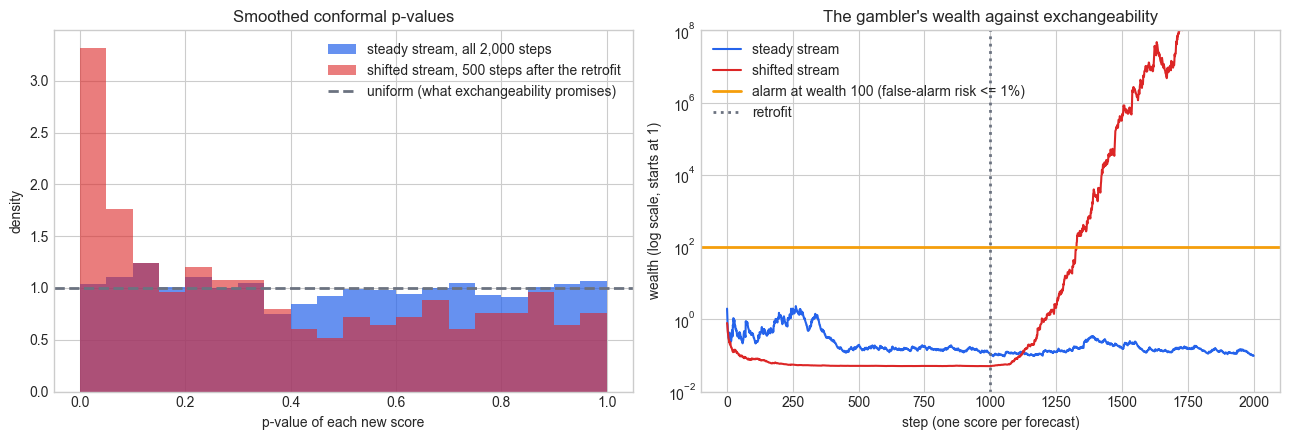

In [13]:
EPS_GRID = np.linspace(0.05, 1.0, 20)   # betting intensities; epsilon = 1 never bets
ALARM_AT = 100.0                        # Ville: P(false alarm, ever) <= 1 / 100


def smoothed_conformal_p_values(scores, rng):
    """Sequential smoothed conformal p-values, one per score, for one or many streams.

    `scores` is a 1-D stream or a 2-D array with one stream per row. At step n the newest
    score s_n is ranked among ALL n scores so far, itself included:
        p_n = (#{i <= n: s_i > s_n} + U_n * #{i <= n: s_i == s_n}) / n,
    with U_n uniform on (0, 1]. Large scores (strange) get small p-values. Under
    exchangeability the p-values are independent and exactly uniform on [0, 1]
    (Vovk, Nouretdinov and Gammerman 2003); the random tie-break is what makes them
    exactly uniform rather than discrete.
    """
    S = np.atleast_2d(np.asarray(scores, dtype=float))
    U = 1.0 - rng.random(S.shape)                  # uniform on (0, 1], so p is never 0
    p = np.empty(S.shape)
    for n in range(S.shape[1]):
        seen, new = S[:, : n + 1], S[:, n : n + 1]   # every score so far, the new one included
        greater = (seen > new).sum(axis=1)
        ties = (seen == new).sum(axis=1)             # at least 1: the new score itself
        p[:, n] = (greater + U[:, n] * ties) / (n + 1)
    return p


def log_conformal_martingale(p, eps_grid=EPS_GRID):
    """Log-wealth of the power martingale prod(eps * p_i**(eps - 1)), mixed uniformly
    over a grid of betting intensities, after every step. Computed in log space because
    the product of thousands of p-values underflows in floating point.
    Returns an array shaped like `p` (one row per stream)."""
    n = np.arange(1, p.shape[1] + 1)[:, None]
    cum_log_p = np.cumsum(np.log(p), axis=1)[:, :, None]
    log_m = n * np.log(eps_grid) + cum_log_p * (eps_grid - 1.0)   # (streams, steps, grid)
    return logsumexp(log_m, axis=2) - np.log(len(eps_grid))


rng = np.random.default_rng(RANDOM_SEED + 7)
p_steady = smoothed_conformal_p_values(steady, rng)[0]
p_shifted = smoothed_conformal_p_values(shifted, rng)[0]
wealth_steady = np.exp(log_conformal_martingale(p_steady[None, :])[0])
wealth_shifted = np.exp(log_conformal_martingale(p_shifted[None, :])[0])
first_alarm = int(np.argmax(wealth_shifted >= ALARM_AT)) + 1

print(f"steady stream:  mean p-value {p_steady.mean():.3f} | highest wealth ever {wealth_steady.max():.2f}"
      f" | alarms: {int((wealth_steady >= ALARM_AT).any())}")
print(f"shifted stream: mean p-value before the retrofit {p_shifted[:SHIFT_AT].mean():.3f}, "
      f"in the 500 steps after it {p_shifted[SHIFT_AT:SHIFT_AT + 500].mean():.3f}")
print(f"shifted stream: wealth first reaches {ALARM_AT:.0f} at step {first_alarm:,} "
      f"({first_alarm - SHIFT_AT} steps after the retrofit); final wealth {wealth_shifted[-1]:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.linspace(0.0, 1.0, 21)
axes[0].hist(p_steady, bins=bins, color=BLUE, alpha=0.7, density=True, label="steady stream, all 2,000 steps")
axes[0].hist(p_shifted[SHIFT_AT:SHIFT_AT + 500], bins=bins, color=RED, alpha=0.6, density=True,
             label="shifted stream, 500 steps after the retrofit")
axes[0].axhline(1.0, color=GRAY, ls="--", lw=2, label="uniform (what exchangeability promises)")
axes[0].set_title("Smoothed conformal p-values")
axes[0].set_xlabel("p-value of each new score")
axes[0].set_ylabel("density")
axes[0].legend(loc="upper right")
axes[1].plot(np.arange(1, T + 1), wealth_steady, color=BLUE, label="steady stream")
axes[1].plot(np.arange(1, T + 1), wealth_shifted, color=RED, label="shifted stream")
axes[1].axhline(ALARM_AT, color=AMBER, lw=2, label="alarm at wealth 100 (false-alarm risk <= 1%)")
axes[1].axvline(SHIFT_AT, color=GRAY, ls=":", lw=2, label="retrofit")
axes[1].set_yscale("log")
axes[1].set_ylim(1e-2, 1e8)
axes[1].set_title("The gambler's wealth against exchangeability")
axes[1].set_xlabel("step (one score per forecast)")
axes[1].set_ylabel("wealth (log scale, starts at 1)")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

The left panel is the theorem made visible. On the steady stream the 2,000 p-values are flat across $[0, 1]$, mean 0.493, as exchangeability promises. In the 500 steps after the retrofit, the shifted stream's p-values pile up near zero (mean 0.392): newer scores keep landing near the top of the leaderboard. The right panel is the gambler. On the steady stream her wealth peaks at 2.33 early on, nowhere near the alarm line, and then sinks: a fair game slowly ruins an aggressive bettor, so the wealth drifts down toward the floor of 0.05 held by the share of the starting unit placed on $\varepsilon = 1$, which never bets (1/20 of it). On the shifted stream the wealth sits on that floor until the retrofit, then compounds: it crosses 100 at step 1,328, 328 steps after the change, and ends the run above $10^{11}$ (the plot is clipped at $10^{8}$).

That floor has a practical cost worth knowing before you deploy. After a long healthy stretch the climb to 100 is a factor of 2,000, not 100, which is part of why this stream needed 328 steps. Monitors meant to run for months therefore usually use change-point versions built on the same conformal p-values, which restart the bet instead of letting the wealth sink (Vovk and colleagues describe CUSUM and Shiryaev-Roberts variants, 2021). What the alarm does not mean: it does not say what changed, only that the scores stopped being exchangeable with their own past. Neither does a quiet martingale prove exchangeability; it means no evidence has accumulated yet. The next cell checks both promises at scale: the false-alarm bound on many healthy streams, and the detection delay on many shifted ones.

independent scores (exchangeable)    share of streams ever reaching 100: 0.005 | reaching 10: 0.040


hourly AR(1) scores, 2,000 hours     share of streams ever reaching 100: 0.250 | reaching 10: 0.465


the same AR(1) scores, one per day   share of streams ever reaching 100: 0.005 | reaching 10: 0.055



shifted streams: alarms before the retrofit 2 of 200 | detected by step 2,000: 198 of 200
detection delay after the retrofit: median 174 steps, 90th percentile 273 steps



the same AR(1) scores, daily mean of 24 share of streams ever reaching 100: 0.005 | reaching 10: 0.060
correlation between consecutive daily means: 0.046


60% jump at day 1,000, one reading kept per day  : alarms before the jump 0 of 200 | detected 200 of 200 | delay median 190 days, 90th percentile 289 days


60% jump at day 1,000, daily mean of 24 readings : alarms before the jump 3 of 200 | detected 197 of 200 | delay median 67 days, 90th percentile 99 days


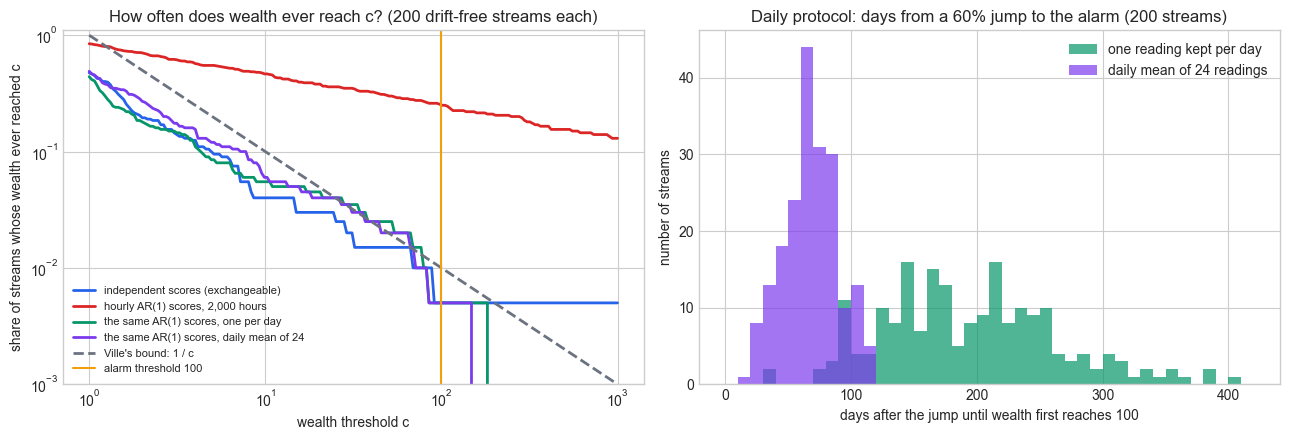

In [14]:
def first_alarm_step(log_wealth):
    """Step (1-based) at which each stream's wealth first reaches ALARM_AT; -1 if never."""
    crossed = log_wealth >= np.log(ALARM_AT)
    return np.where(crossed.any(axis=1), crossed.argmax(axis=1) + 1, -1)


R = 200
rng = np.random.default_rng(RANDOM_SEED + 8)
iid_streams = np.abs(rng.normal(size=(R, T)))
shifted_streams = np.abs(rng.normal(size=(R, T))) * np.where(after_shift, 1.6, 1.0)

# Drift-free but autocorrelated: hourly errors with the same AR(1) memory (0.8) as the
# noise in simulate_building_load. Exchangeable? No - neighbours resemble each other.
PHI, HOURS = 0.8, 24 * T
z = rng.normal(size=(R, HOURS))
ar = np.empty((R, HOURS))
ar[:, 0] = z[:, 0]
for i in range(1, HOURS):
    ar[:, i] = PHI * ar[:, i - 1] + math.sqrt(1 - PHI ** 2) * z[:, i]
families = {
    "independent scores (exchangeable)": iid_streams,
    "hourly AR(1) scores, 2,000 hours": np.abs(ar[:, :T]),
    "the same AR(1) scores, one per day": np.abs(ar[:, ::24]),
}

max_wealth = {}
for name, streams in families.items():
    log_w = log_conformal_martingale(smoothed_conformal_p_values(streams, rng))
    max_wealth[name] = np.exp(log_w.max(axis=1))
    print(f"{name:<36} share of streams ever reaching 100: {np.mean(max_wealth[name] >= ALARM_AT):.3f}"
          f" | reaching 10: {np.mean(max_wealth[name] >= 10):.3f}")

alarm_step = first_alarm_step(log_conformal_martingale(smoothed_conformal_p_values(shifted_streams, rng)))
early = (alarm_step > 0) & (alarm_step <= SHIFT_AT)
delays = alarm_step[alarm_step > SHIFT_AT] - SHIFT_AT
print(f"\nshifted streams: alarms before the retrofit {early.sum()} of {R} | detected by step {T:,}: "
      f"{(alarm_step > SHIFT_AT).sum()} of {R}")
print(f"detection delay after the retrofit: median {np.median(delays):.0f} steps, "
      f"90th percentile {np.percentile(delays, 90):.0f} steps")

# The project's protocol: ONE SCORE PER DAY from the same hourly AR(1) errors, either one
# reading kept per day (thinned) or the mean of the day's 24 scores (aggregated). Each step
# is now a day, so delays are in days. For detection, the same errors are made 60% larger
# from day 1,000 on (a retrofit); before that day the shifted streams equal the drift-free ones.
daily_kept = np.abs(ar[:, ::24])
daily_mean = np.abs(ar).reshape(R, T, 24).mean(axis=2)
mean_name = "the same AR(1) scores, daily mean of 24"
log_w_mean = log_conformal_martingale(smoothed_conformal_p_values(daily_mean, rng))
max_wealth[mean_name] = np.exp(log_w_mean.max(axis=1))
print(f"\n{mean_name:<36} share of streams ever reaching 100: {np.mean(max_wealth[mean_name] >= ALARM_AT):.3f}"
      f" | reaching 10: {np.mean(max_wealth[mean_name] >= 10):.3f}")
# Daily means are only NEARLY exchangeable: the end of one day and the start of the next share memory.
lag1 = np.corrcoef(daily_mean[:, :-1].ravel(), daily_mean[:, 1:].ravel())[0, 1]
print(f"correlation between consecutive daily means: {lag1:.3f}")
day_jump = np.where(after_shift, 1.6, 1.0)
daily_delays = {}
for name, daily in [("one reading kept per day", daily_kept), ("daily mean of 24 readings", daily_mean)]:
    alarm_day = first_alarm_step(log_conformal_martingale(smoothed_conformal_p_values(daily * day_jump, rng)))
    daily_delays[name] = alarm_day[alarm_day > SHIFT_AT] - SHIFT_AT
    print(f"60% jump at day {SHIFT_AT:,}, {name:<26}: alarms before the jump "
          f"{((alarm_day > 0) & (alarm_day <= SHIFT_AT)).sum()} of {R} | detected {len(daily_delays[name])} of {R}"
          f" | delay median {np.median(daily_delays[name]):.0f} days, 90th percentile "
          f"{np.percentile(daily_delays[name], 90):.0f} days")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
c_grid = np.logspace(0, 3, 200)
for (name, mw), color in zip(max_wealth.items(), [BLUE, RED, GREEN, PURPLE]):
    axes[0].plot(c_grid, [np.mean(mw >= c) for c in c_grid], color=color, lw=2, label=name)
axes[0].plot(c_grid, 1 / c_grid, color=GRAY, ls="--", lw=2, label="Ville's bound: 1 / c")
axes[0].axvline(ALARM_AT, color=AMBER, lw=1.5, label="alarm threshold 100")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-3, 1.1)
axes[0].set_title(f"How often does wealth ever reach c? ({R} drift-free streams each)")
axes[0].set_xlabel("wealth threshold c")
axes[0].set_ylabel("share of streams whose wealth ever reached c")
axes[0].legend(loc="lower left", fontsize=8)
delay_bins = np.arange(0, max(d.max() for d in daily_delays.values()) + 20, 10)
axes[1].hist(daily_delays["one reading kept per day"], bins=delay_bins, color=GREEN, alpha=0.7,
             label="one reading kept per day")
axes[1].hist(daily_delays["daily mean of 24 readings"], bins=delay_bins, color=PURPLE, alpha=0.7,
             label="daily mean of 24 readings")
axes[1].set_title(f"Daily protocol: days from a 60% jump to the alarm ({R} streams)")
axes[1].set_xlabel("days after the jump until wealth first reaches 100")
axes[1].set_ylabel("number of streams")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

Start with the promise. Of 200 streams that are exchangeable by construction, one ever reached wealth 100 in 2,000 steps (0.005, against Ville's ceiling of 0.01), and 0.040 ever reached 10 (ceiling 0.10). In the left panel the blue curve sits below the gray $1/c$ line all the way to the alarm threshold: Ville's inequality is a ceiling, and a mixture martingale usually stays well under it. Beyond 100 the blue curve flattens at 0.005, which is one stream. Two hundred streams cannot measure a probability smaller than 1 in 200, so that flat tail is the resolution of the experiment, not a breach of the bound: even if the chance of ever reaching 1,000 were exactly 0.001, one of 200 streams would get there with probability $1 - 0.999^{200} \approx 0.18$. The shifted streams are exchangeable until step 1,000, so they are another 200 healthy streams for that stretch: two of them alarmed before the retrofit (0.010, right at the ceiling; pooled with the independent streams, 3 of 400). False alarms, when they happen, tend to happen early, when a handful of extreme p-values can move a gambler who bets hard. The other 198 streams all alarmed after the retrofit, with a median delay of 174 steps and a 90th percentile of 273. A 60% jump in error size is found within a few hundred scores, and the threshold says in advance how often you will be woken up for nothing. "Scores" is the unit that matters: the next paragraph shows what it becomes in days.

Now the caution that matters most for the project. The red curve is 200 hourly error streams with the same AR(1) memory as `simulate_building_load`'s noise, and no drift at all: 0.250 of them crossed 100. That is not a false alarm in the statistical sense. Autocorrelated scores are not exchangeable (neighbours resemble each other, so a position is special), and the martingale is doing its job. But it means a martingale on raw hourly scores answers "is this stream exchangeable?", whose answer for any hourly meter is no, rather than "did something change?". The fix is to feed the test one score per day. Keeping one reading per day (green; the correlation between the underlying errors 24 hours apart is $0.8^{24} \approx 0.005$) behaves like the independent streams, with 0.005 crossing 100, one stream of 200. Averaging each day's 24 scores (purple) is just as quiet at the alarm line, 0.005, although consecutive daily means still share a little memory (correlation 0.046), so they are nearly, not exactly, exchangeable. Where a green or purple curve pokes slightly above the gray line, between roughly $c = 30$ and $c = 70$, the excursion is one or two streams out of 200, within what 200 streams can resolve.

Then the price, and here the units matter: on the daily protocol every step is a day. When the same hourly errors grow 60% from day 1,000 on, keeping one reading per day took a median of 190 days to alarm (90th percentile 289). The daily mean, which keeps the evidence of all 24 readings, took 67 days (90th percentile 99): the right panel. The daily mean also raised 3 alarms before the jump among its 200 streams, 0.015. That is above the 0.01 ceiling, but three or more of 200 happen about one run in three even at exactly 1%, and daily means are only nearly exchangeable, so read it as a reminder that thinning and averaging buy approximate validity, not the exact kind. The honest summary for the project: on daily scores the conformal test martingale is a slow, safe alarm. It needs months, not days, to flag a 60% jump after nearly three quiet years, partly because the wealth must first climb back from its floor. It is the right instrument for deciding when to stop quoting a split-conformal guarantee in a report, not for paging an engineer. Faster detection needs the change-point variants mentioned above, or the online methods of notebook 15, which adapt without waiting for a verdict.

Here are the four tools side by side. The fourth is the domain classifier from notebook 07, which belongs in every monitoring kit because it needs no labels.

| Test | What it looks at | Needs the truth? | What it answers | Pitfall |
|---|---|---|---|---|
| Look: rolling score mean and coverage | scores over time | yes | "does anything move?" | subjective; a healthy stream dipped to 0.79 |
| Permutation test | calibration window vs a recent window | yes | "is this window different?" (one look) | valid for one look; 14 looks raised an alarm on 0.370 of healthy streams |
| Domain classifier (notebook 07) | features, calibration vs recent | no | "did the input mix change?" | blind to concept drift (AUC 0.51 in section 4) |
| Conformal test martingale | every score, as it arrives | yes | "are the scores still exchangeable?", at every step | fires on autocorrelation alone (0.250 of drift-free hourly streams); feed it daily means, and expect months, not days (median 67 days for a 60% jump) |

Tied back to the forecasting project, the martingale is the drift alarm. Run it on each series' calibration-era scores (aggregated to daily means) and keep it running in production. The moment the wealth crosses 100, stop quoting the split-conformal guarantee for that series and switch it to online calibration (notebook 15), whose promise does not depend on exchangeability at all.

## 6. What to do when the answer is no

A test that says "not exchangeable" is the start of a decision, not the end of the analysis. The table maps each violation to the method that answers it, what that method actually guarantees, and what it costs.

| Violation | Method | What it guarantees | Cost | Where |
|---|---|---|---|---|
| Covariate shift | weighted conformal with the likelihood ratio | at least $1 - \alpha$ with the true ratio; approximately with an estimated one | smaller effective sample size, wider and sometimes infinite bands | notebook 07 |
| Groups / new site | group-aware splits; building-level calibration | about 90% on average over new sites (row-level pool), or at least 90% for a new site with probability at least 90% (building-level) | the per-site lottery remains, or bands 23% wider and at least nine calibration sites | section 3 |
| Label shift | class-conditional calibration, or reweighting by class shares | at least $1 - \alpha$ within each class, hence under any class mix | longer sets; enough calibration rows per class; reweighting needs the new mix | notebook 04 |
| Slow drift in time | recency-weighted calibration with fixed weights (Barber, Candès, Ramdas and Tibshirani 2023) | coverage falls short of $1 - \alpha$ by at most a weighted total-variation distance (in words below) | the bound is not computable from data alone; fewer effective scores | notebook 15 |
| Any sequence at all | ACI and conformal PID | the long-run miss rate converges to $\alpha$ for any sequence, even an adversarial one | nothing per week; ACI can emit infinite bands | notebook 15 |
| Concept drift | collect new labels, retrain, recalibrate on post-change data | split conformal again, once post-change data are exchangeable with the future | waiting for labels; the martingale tells you when to start | field guide §10 |
| Selection and feedback | a random exploration sample; logged propensities and inverse-probability weights | a weighted guarantee on the full population (a covariate shift with a known ratio) | acting at random on some cases | notebook 07's machinery |

The Barber, Candès, Ramdas and Tibshirani result ("conformal prediction beyond exchangeability") deserves its sentence in words, because it is the theoretical floor under every rolling window in Part II. Put fixed weights on the calibration scores, chosen before seeing the data (for example, larger for recent scores), and use the weighted quantile with the test point's own weight at $+\infty$, exactly as notebook 07 did. Then coverage can fall below $1 - \alpha$ by at most the weighted average, over calibration points, of how much the joint distribution of the data would change if that point swapped places with the test point (a total-variation distance). Old points that look nothing like today are charged a lot; recent points that resemble today are charged almost nothing. So weights concentrated on the recent past keep the shortfall small when the world drifts slowly, and with equal weights on exchangeable data the charge is zero and the classic guarantee returns. Notebook 15 implements it.

Finally, the sentence a student can put in a thesis, with the brackets filled from their own analysis: "We assume that calibration and test scores are exchangeable at the level of [rows within a building / buildings within the portfolio]. We tested this with [a conformal test martingale on daily mean scores, alarm at wealth 100, false-alarm probability at most 1% by Ville's inequality for exchangeable scores] and [a permutation test of the most recent four weeks against the calibration window]. Where the tests rejected ([series, period]), we replaced split conformal with [method], which guarantees [statement] instead." Four parts: what assumption, at which level, how it was tested, and which method was used where it failed.

## 7. Common mistakes to avoid

1. **Checking independence instead of exchangeability.** In section 2 a strict i.i.d. check rejected both plans, the one that covered 0.901 and the one that covered 0.761, so it could not tell them apart. The usual shortcut ("is the test set independent of the calibration set?") did worse: it rejected the first and approved the second. Ask whether a test row could swap places with a calibration row unnoticed, and say how the rows were chosen (field guide §13).
2. **Quoting the portfolio average for one building.** Leave-one-building-out coverage averaged 0.899 and ranged from 0.812 to 0.954 per building (section 3). A promise to one site needs building-level calibration, and it costs width (field guide §13, field guide §3).
3. **Reweighting concept drift.** When P(y | x) moves, the inputs look the same (domain classifier AUC 0.51), so estimated weights carry no information, while coverage sits at 0.849. Write the stability sentence first; if you cannot, collect new labels (field guide §10).
4. **Calibrating on the cases you acted on.** The band covered 0.912 of the acted-on cases and 0.763 of the population it was quoted for (section 4f). Keep a random exploration sample, or the calibration set inherits your decision rule (field guide §6).
5. **Running a fixed-level test on a schedule.** Fourteen looks at the 5% level alarmed on 0.370 of healthy streams. For continuous monitoring use an anytime-valid test, the conformal test martingale, whose false-alarm probability is bounded by Ville's inequality no matter how often you look (field guide §14).
6. **Feeding raw hourly scores to the martingale and calling the alarm drift.** Autocorrelation alone sent 0.250 of drift-free hourly streams past wealth 100. One score per day, whether one kept reading or the daily mean of 24, sent 0.005, the same as independent scores. Decide what the test should be sensitive to, then aggregate: daily means flagged a 60% jump in a median of 67 days, a single kept reading per day in 190 (field guide §14).
7. **Treating a quiet test as proof.** No alarm means no evidence yet, not exchangeability: on daily means a 60% jump in error size took a median of 67 days to detect after a long quiet stretch, and 99 days at the 90th percentile. Quote the guarantee after the test, name the test and its detection delay in days, and keep it running (field guide §14).

## 8. What to say in the project report

> **Strong version:** "We treat buildings, not hours, as the exchangeable unit. Calibrating on ten simulated buildings and testing on the eleventh gave a mean coverage of 0.899 across held-out buildings but 0.812 to 0.954 for individual buildings, so we report the 90% band as an average over new sites; where a per-site promise is needed we calibrate at the building level (10 of 11 buildings at or above 0.90, for bands 23% wider). We test exchangeability with a conformal test martingale on daily mean scores, alarming at wealth 100; Ville's inequality bounds the false-alarm probability at 1% for exchangeable scores, and daily means are nearly so (correlation 0.046 between consecutive days). In simulation it alarmed on 1 of 200 drift-free daily-mean streams and detected a 60% increase in error size after a median of 67 days (99 days at the 90th percentile), so we treat it as the signal to stop quoting a guarantee, not as an operational alarm. Raw hourly scores trigger the test through autocorrelation alone, which is why we aggregate them to daily means. Where the test fires, we stop quoting the split-conformal guarantee for that series and switch to online calibration."

> **Weak version:** "Conformal prediction requires i.i.d. data. Our hourly meter readings are autocorrelated, so the assumption is violated, but a random 80/20 split of all rows gave 90% coverage, which shows the bands are valid for the portfolio, including new buildings."

The weak version reasons from the wrong property and then ignores its own conclusion. Correlation alone does not void the guarantee (section 2's correlated plan covered 0.901). What matters is whether future rows could swap with calibration rows, and for hourly meters they cannot, because next month is not a random draw from last month and a new building is not a row of an old one. Having declared the assumption violated, it then validates on a random row split, which answers "a random hour of a building we already have" and says nothing about a new building or next month. And it never tests anything. The strong version names the level, quotes the spread, names the test and its false-alarm bound, and says what happens when the test fires.

### The one-line summary

The 90% promise needs one thing: that the newcomer could be swapped with any calibration row without anyone noticing. That is weaker than independence: correlated rows that share a hidden cause qualify, and a test set that is independent of its calibration set can still fail, because the calibration rows share a cause the test rows do not. It lives at a level, rows or buildings, that you must name. It fails in at least six distinct ways, each with its own repair, and it can be tested, finally, with a gambler whose wealth crosses 100 on an exchangeable stream with probability at most 1%, however long you watch.

Exchangeability is not something your data has; it is something your sampling earns.